In [1]:
import pandas as pd  # Importar pandas para manejo de datos
import numpy as np  # Importar numpy para operaciones numéricas
from sklearn import preprocessing  # Importar preprocesamiento (LabelEncoder)
from sklearn.model_selection import train_test_split  # Importar función para dividir datos
from sklearn.linear_model import LogisticRegression  # Importar modelo de Regresión Logística
from sklearn.metrics import classification_report, roc_curve, roc_auc_score  # Importar métricas y curva ROC
from sklearn import metrics  # Importar módulo de métricas generales
import matplotlib.pyplot as plt  # Importar módulo para graficar
import warnings  # Importar módulo de advertencias del sistema
warnings.filterwarnings("ignore")  # Ocultar advertencias en la salida

In [2]:
url = "https://raw.githubusercontent.com/JoseRaulCastro/EBAC/main/drugs.csv"
df = pd.read_csv(url)  # Cargar CSV desde la URL
print("Dimensiones:", df.shape)
print("Categorías en Drug:", df["Drug"].value_counts(dropna=False))
df.head()

Dimensiones: (200, 6)
Categorías en Drug: Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [3]:
# Convertir variables predictoras cualitativas a escala numérica con LabelEncoder
le_sex = preprocessing.LabelEncoder()
le_bp = preprocessing.LabelEncoder()
le_chol = preprocessing.LabelEncoder()

df["Sex_num"] = le_sex.fit_transform(df["Sex"])  # Codificar Sexo
df["BP_num"] = le_bp.fit_transform(df["BP"])  # Codificar Presión arterial
df["Cholesterol_num"] = le_chol.fit_transform(df["Cholesterol"])  # Codificar Colesterol

print("Mapeo Sex:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Mapeo BP:", dict(zip(le_bp.classes_, le_bp.transform(le_bp.classes_))))
print("Mapeo Cholesterol:", dict(zip(le_chol.classes_, le_chol.transform(le_chol.classes_))))

# Transformar variable objetivo según tipo de proveedor:
proveedores_extranjeros = {"drugX", "drugY"}
df["Proveedor_extranjero"] = df["Drug"].apply(lambda val: 1 if val in proveedores_extranjeros else 0)

print("\nDistribución variable objetivo (0 = Nacional, 1 = Extranjero):")
print(df["Proveedor_extranjero"].value_counts())
df.head()

Mapeo Sex: {'F': 0, 'M': 1}
Mapeo BP: {'HIGH': 0, 'LOW': 1, 'NORMAL': 2}
Mapeo Cholesterol: {'HIGH': 0, 'NORMAL': 1}

Distribución variable objetivo (0 = Nacional, 1 = Extranjero):
Proveedor_extranjero
1    145
0     55
Name: count, dtype: int64


,Age,Sex,BP,Cholesterol,Na_to_K,Drug,Sex_num,BP_num,Cholesterol_num,Proveedor_extranjero
0,23,F,HIGH,HIGH,25.355,drugY,0,0,0,1
1,47,M,LOW,HIGH,13.093,drugC,1,1,0,0
2,47,M,LOW,HIGH,10.114,drugC,1,1,0,0
3,28,F,NORMAL,HIGH,7.798,drugX,0,2,0,1
4,61,F,LOW,HIGH,18.043,drugY,0,1,0,1


In [4]:
# Selección de las características y variable objetivo
feature_cols = ["Age", "Sex_num", "BP_num", "Cholesterol_num", "Na_to_K"]  # Variables predictoras
X = df[feature_cols]  # Variables independientes
y = df["Proveedor_extranjero"]  # Variable objetivo binaria

In [5]:
# Creación de las bases de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)  # Dividir datos

In [6]:
# Regresión logística con solucionador (solver): sag
model = LogisticRegression(solver="sag", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test)  # Generar predicciones

print("Intercepto (Beta0): ", clf.intercept_)  # Imprimir intercepto
print("Pesos (Betas): ", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Precisión global: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta0):  [-5.05186571]
Pesos (Betas):  [[-0.01844533 -0.16398295  2.26782889  1.25341096  0.34902931]]
----------------------------------------------------------------------------------------------------
Precisión global:  0.975
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [7]:
# Regresión logística con solucionador (solver): newton-cg
model = LogisticRegression(solver="newton-cg", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test)  # Generar predicciones

print("Intercepto (Beta0): ", clf.intercept_)  # Imprimir intercepto
print("Pesos (Betas): ", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Precisión global: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta0):  [-11.15250574]
Pesos (Betas):  [[0.00660821 0.14830519 3.33610201 2.0724554  0.63787638]]
----------------------------------------------------------------------------------------------------
Precisión global:  0.975
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [8]:
# Regresión logística con solucionador (solver): liblinear
model = LogisticRegression(solver="liblinear", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test)  # Generar predicciones

print("Intercepto (Beta0): ", clf.intercept_)  # Imprimir intercepto
print("Pesos (Betas): ", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Precisión global: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta0):  [-3.34051275]
Pesos (Betas):  [[-0.02834219 -0.26053256  2.06969328  1.09570978  0.27510142]]
----------------------------------------------------------------------------------------------------
Precisión global:  0.975
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [9]:
# Regresión logística con solucionador (solver): saga
model = LogisticRegression(solver="saga", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test)  # Generar predicciones

print("Intercepto (Beta0): ", clf.intercept_)  # Imprimir intercepto
print("Pesos (Betas): ", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Precisión global: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta0):  [-2.92372851]
Pesos (Betas):  [[-0.02916835 -0.31239437  1.96301755  0.93883319  0.25906158]]
----------------------------------------------------------------------------------------------------
Precisión global:  0.975
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



In [10]:
# Regresión logística con solucionador (solver): lbfgs
model = LogisticRegression(solver="lbfgs", max_iter=5000)  # Crear modelo
clf = model.fit(X_train, y_train)  # Entrenar modelo

y_pred = model.predict(X_test)  # Generar predicciones

print("Intercepto (Beta0): ", clf.intercept_)  # Imprimir intercepto
print("Pesos (Betas): ", clf.coef_)  # Imprimir coeficientes
print("----------------------------------------------------------------------------------------------------")
score = model.score(X_test, y_test)  # Calcular exactitud del modelo
print("Precisión global: ", score)  # Imprimir precisión global
print("----------------------------------------------------------------------------------------------------")
print(classification_report(y_test, y_pred))  # Generar e imprimir reporte de clasificación

Intercepto (Beta0):  [-11.16791614]
Pesos (Betas):  [[0.00667297 0.14894912 3.33863745 2.07461152 0.63862512]]
----------------------------------------------------------------------------------------------------
Precisión global:  0.975
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.97      1.00      0.98        30

    accuracy                           0.97        40
   macro avg       0.98      0.95      0.97        40
weighted avg       0.98      0.97      0.97        40



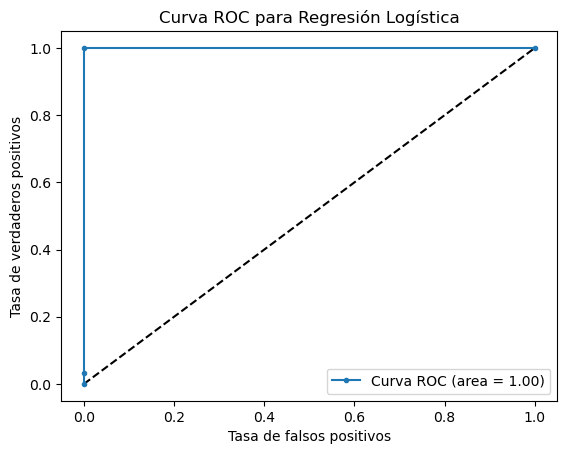

In [11]:
# Predicción de probabilidades y Curva ROC (usando el modelo entrenado)
y_pred_probs = clf.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva (1)
y_test_arr = np.asarray(y_test, dtype=int)

fpr, tpr, thresholds = roc_curve(y_test_arr, y_pred_probs)
auc = roc_auc_score(y_test_arr, y_pred_probs)

plt.plot([0, 1], [0, 1], "k--")  # Línea diagonal de referencia
plt.plot(fpr, tpr, marker=".", label="Curva ROC (area = %0.2f)" % auc)  # Curva ROC con AUC
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.title("Curva ROC para Regresión Logística")
plt.show()